# Import Libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as npσ
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler

TASK 1

In [3]:
df = pd.read_csv('airline_passenger_satisfaction.csv')
df

,ID,Gender,Age,Customer Type,Type of Travel,Class,Flight Distance,Departure Delay,Arrival Delay,Departure and Arrival Time Convenience,...,On-board Service,Seat Comfort,Leg Room Service,Cleanliness,Food and Drink,In-flight Service,In-flight Wifi Service,In-flight Entertainment,Baggage Handling,Satisfaction
0,1,Male,48,First-time,Business,Business,821.0,2.0,5.0,3.0,...,3.0,5.0,2.0,5.0,5.0,5.0,3.0,5.0,5.0,Neutral or Dissatisfied
1,2,Female,35,Returning,Business,Business,821.0,26.0,39.0,2.0,...,5.0,4.0,5.0,5.0,3.0,5.0,2.0,5.0,5.0,Satisfied
2,3,Male,41,Returning,Business,Business,853.0,0.0,0.0,4.0,...,3.0,5.0,3.0,5.0,5.0,3.0,4.0,3.0,3.0,Satisfied
3,4,Male,50,Returning,Business,Business,1905.0,0.0,0.0,2.0,...,5.0,5.0,5.0,4.0,4.0,5.0,2.0,5.0,5.0,Satisfied
4,5,Female,49,Returning,Business,Business,3470.0,0.0,1.0,3.0,...,3.0,4.0,4.0,5.0,4.0,3.0,3.0,3.0,3.0,Satisfied
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10721,10722,Male,33,Returning,Business,Business,312.0,11.0,52.0,2.0,...,2.0,1.0,4.0,1.0,1.0,3.0,1.0,1.0,3.0,Neutral or Dissatisfied
10722,10723,Female,15,First-time,Business,Economy,312.0,75.0,87.0,4.0,...,4.0,5.0,3.0,5.0,5.0,4.0,3.0,5.0,4.0,Neutral or Dissatisfied
10723,10724,Female,57,Returning,Business,Business,2667.0,89.0,78.0,5.0,...,2.0,4.0,2.0,5.0,4.0,2.0,0.0,2.0,2.0,Satisfied
10724,10725,Male,58,Returning,Business,Business,201.0,0.0,0.0,1.0,...,4.0,5.0,4.0,4.0,4.0,4.0,1.0,4.0,5.0,Satisfied


In [4]:
df = df.dropna() #  we have null values so the simplest solution is to drop the rows that contain nan (instead of using imputation)


In [5]:
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns
categorical_cols = df.select_dtypes(include=['object']).columns

In [6]:
numerical_cols = numerical_cols.drop('ID')

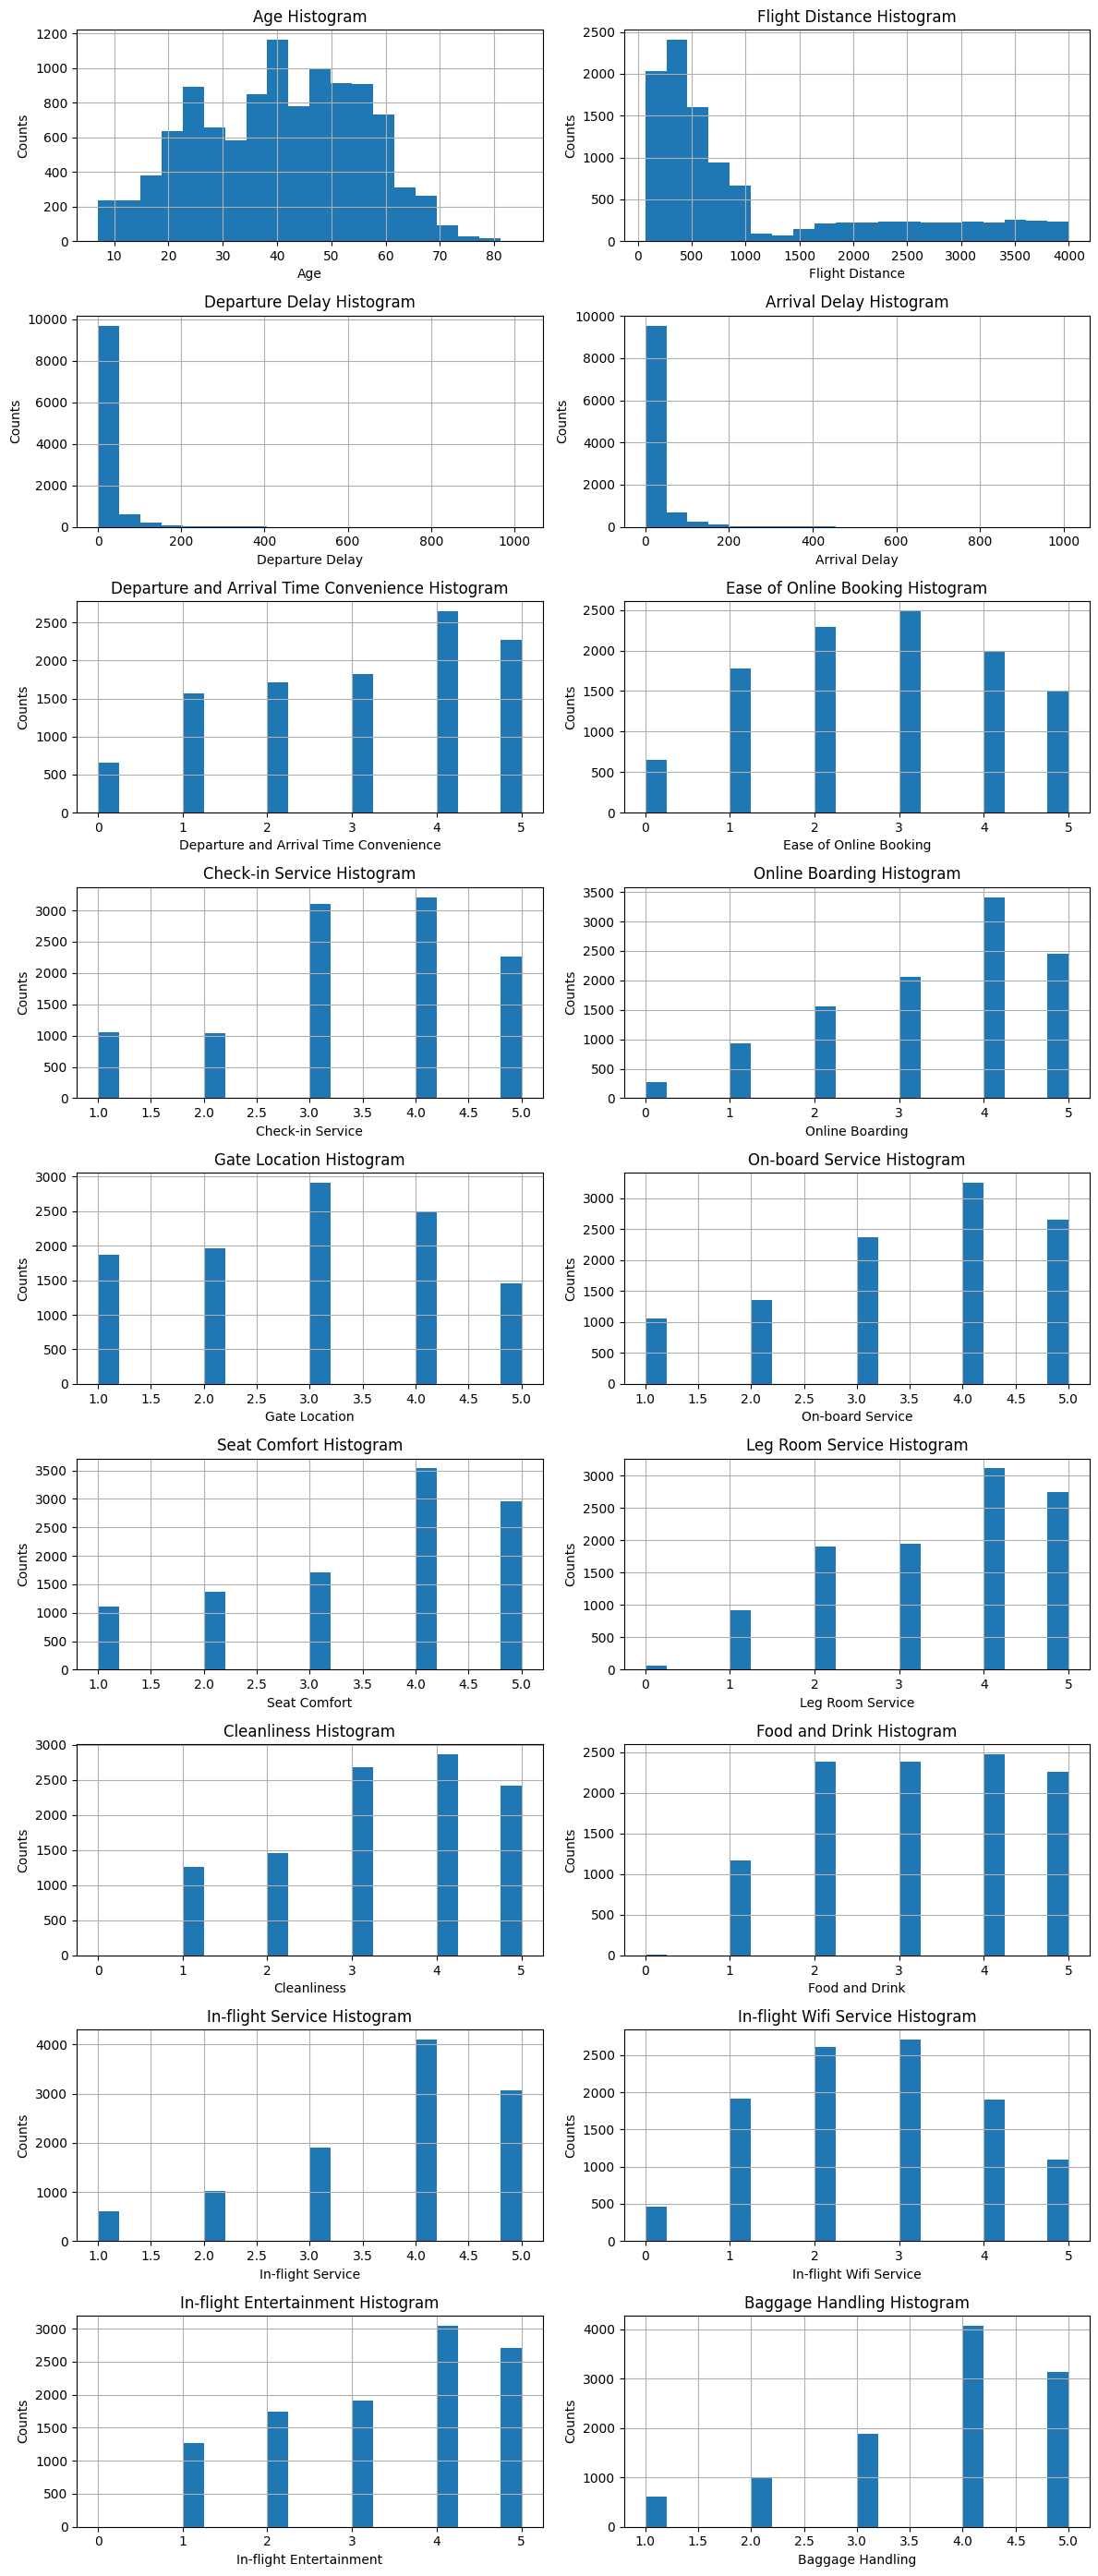

In [7]:
cols_to_plot = numerical_cols

plt.figure(figsize=(12, 28))

for i in range(len(cols_to_plot)):
    col_name = cols_to_plot[i]

    plt.subplot(9, 2, i + 1)
    df[col_name].hist(bins=20)

    plt.title(col_name + ' Histogram')
    plt.xlabel(col_name)
    plt.ylabel('Counts')

plt.tight_layout()
plt.show()

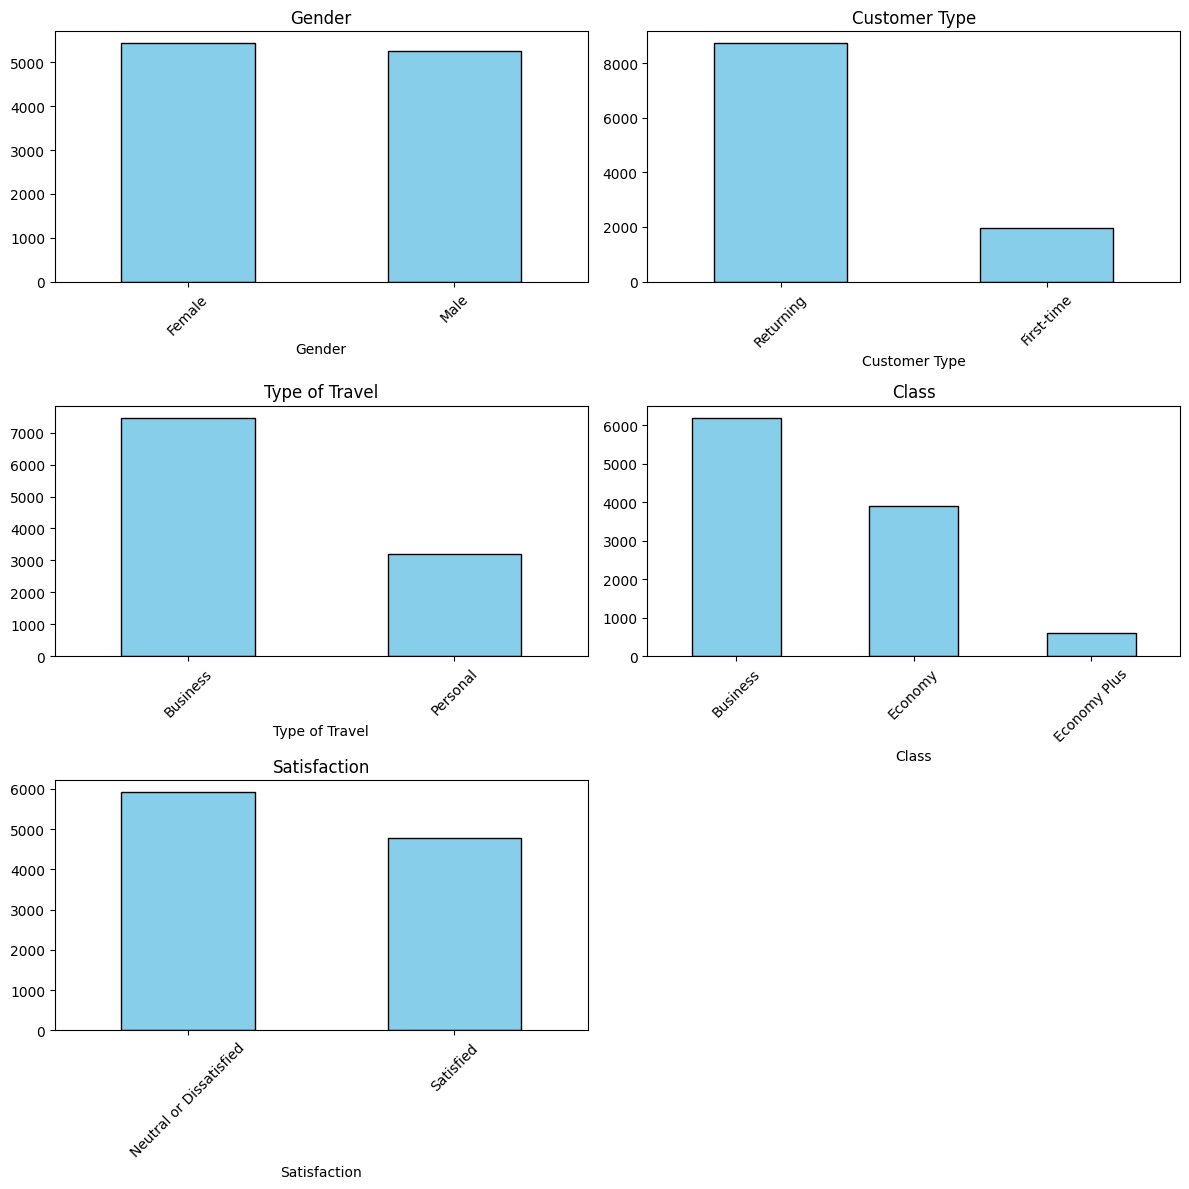

In [8]:

cat_cols = categorical_cols
plt.figure(figsize=(12, 12))
for i in range(len(cat_cols)):
    col_name = cat_cols[i]

    plt.subplot(3, 2, i + 1) # 3x2 = 6 θέσεις (η 6η θα μείνει κενή)
    df[col_name].value_counts().plot(kind='bar', color='skyblue', edgecolor='black')
    plt.title(col_name)
    plt.xticks(rotation=45) # Γυρνάει τις ετικέτες 45 μοίρες για να διαβάζονται εύκολα

plt.tight_layout()
plt.show()

Most of the categorical features are pretty imbalanced. We have way more Returning customers than First-time ones and Business travel is more than double Personal travel. In Class, Economy and Business have the most passengers while Economy Plus has very few. Gender is the only one that's evenly split. Finally, the target variable (Satisfaction) is slightly imbalanced too, with more Neutral or Dissatisfied passengers than Satisfied ones.

In [9]:

df.isnull().sum()

,0
ID,0
Gender,0
Age,0
Customer Type,0
Type of Travel,0
Class,0
Flight Distance,0
Departure Delay,0
Arrival Delay,0
Departure and Arrival Time Convenience,0


TASK 2

In [10]:
df_encoded = df.copy()

# 1. Binary Mapping για τις μεταβλητές με 2 κατηγορίες
df_encoded['Gender'] = df_encoded['Gender'].map({'Female': 0, 'Male': 1})
df_encoded['Customer Type'] = df_encoded['Customer Type'].map({'First-time': 0, 'Returning': 1})
df_encoded['Type of Travel'] = df_encoded['Type of Travel'].map({'Personal': 0, 'Business': 1})
df_encoded['Satisfaction'] = df_encoded['Satisfaction'].map({'Neutral or Dissatisfied': 0, 'Satisfied': 1})

# 2. Ordinal Encoding για την Class (λόγω ιεραρχίας: Economy < Economy Plus < Business)
df_encoded['Class'] = df_encoded['Class'].map({'Economy': 0, 'Economy Plus': 1, 'Business': 2})

df_encoded.head()

,ID,Gender,Age,Customer Type,Type of Travel,Class,Flight Distance,Departure Delay,Arrival Delay,Departure and Arrival Time Convenience,...,On-board Service,Seat Comfort,Leg Room Service,Cleanliness,Food and Drink,In-flight Service,In-flight Wifi Service,In-flight Entertainment,Baggage Handling,Satisfaction
0,1,1,48,0,1,2,821.0,2.0,5.0,3.0,...,3.0,5.0,2.0,5.0,5.0,5.0,3.0,5.0,5.0,0
1,2,0,35,1,1,2,821.0,26.0,39.0,2.0,...,5.0,4.0,5.0,5.0,3.0,5.0,2.0,5.0,5.0,1
2,3,1,41,1,1,2,853.0,0.0,0.0,4.0,...,3.0,5.0,3.0,5.0,5.0,3.0,4.0,3.0,3.0,1
3,4,1,50,1,1,2,1905.0,0.0,0.0,2.0,...,5.0,5.0,5.0,4.0,4.0,5.0,2.0,5.0,5.0,1
4,5,0,49,1,1,2,3470.0,0.0,1.0,3.0,...,3.0,4.0,4.0,5.0,4.0,3.0,3.0,3.0,3.0,1


TASK 3

In [11]:
X = df_encoded.drop('Satisfaction', axis=1).to_numpy()
y = df_encoded['Satisfaction'].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=0
)

TASK 4

In [12]:
from sklearn.preprocessing import MinMaxScaler

feature_cols = df_encoded.drop('Satisfaction', axis=1).columns.tolist()

num_indices = [feature_cols.index(col) for col in cols_to_plot if col in feature_cols]

scaler = MinMaxScaler()

X_train[:, num_indices] = scaler.fit_transform(X_train[:, num_indices])
X_test[:, num_indices] = scaler.transform(X_test[:, num_indices])

We use MinMaxScaler because the numerical features do not follow a normal distribution and scaling them to [0, 1] puts them on the exact same range as our binary (0/1) categorical features. We only normalize the numerical variables (num_indices) so large values like Flight Distance don't dominate the model, while leaving the binary columns untouched since they are already in {0, 1}

In [13]:
import numpy as np

TASK 5

In [17]:
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from math import sqrt
# Το N είναι το πλήθος των παραδειγμάτων εκπαίδευσης
N = X_train.shape[0]

# Οι 6 τιμές του k και οι 2 επιλογές βαρών (6 x 2 = 12 συνδυασμοί)
k_values = [ 3,5,15,51,151,int(sqrt(N)) ]
weight_options = ['uniform', 'distance']

results = []


for k in k_values:
    for w in weight_options:

        knn = KNeighborsClassifier(n_neighbors=k, weights=w, metric='euclidean', n_jobs=-1)

        # train
        knn.fit(X_train, y_train)


        train_acc = accuracy_score(y_train, knn.predict(X_train))
        test_acc = accuracy_score(y_test, knn.predict(X_test))

        results.append({
            'k': k,
            'Weights': w,
            'Train Accuracy': round(train_acc, 4),
            'Test Accuracy': round(test_acc, 4)
        })
        print(f"Ολοκληρώθηκε: k={k}, weights={w}  , Train: {train_acc:.4f}, Test: {test_acc:.4f}")


results_df = pd.DataFrame(results)
display(results_df)


best_row = results_df.loc[results_df['Test Accuracy'].idxmax()]
print("\n Καλύτερος Συνδυασμός ")
print(f"k = {best_row['k']}, weights = '{best_row['Weights']}' με Test Accuracy = {best_row['Test Accuracy']:.4f}")

Ολοκληρώθηκε: k=3, weights=uniform  , Train: 0.8472, Test: 0.6912
Ολοκληρώθηκε: k=3, weights=distance  , Train: 1.0000, Test: 0.6962
Ολοκληρώθηκε: k=5, weights=uniform  , Train: 0.7963, Test: 0.6794
Ολοκληρώθηκε: k=5, weights=distance  , Train: 1.0000, Test: 0.6971
Ολοκληρώθηκε: k=15, weights=uniform  , Train: 0.7266, Test: 0.6575
Ολοκληρώθηκε: k=15, weights=distance  , Train: 1.0000, Test: 0.6962
Ολοκληρώθηκε: k=51, weights=uniform  , Train: 0.6447, Test: 0.5942
Ολοκληρώθηκε: k=51, weights=distance  , Train: 1.0000, Test: 0.6862
Ολοκληρώθηκε: k=151, weights=uniform  , Train: 0.6039, Test: 0.5814
Ολοκληρώθηκε: k=151, weights=distance  , Train: 1.0000, Test: 0.6750
Ολοκληρώθηκε: k=86, weights=uniform  , Train: 0.6043, Test: 0.5777
Ολοκληρώθηκε: k=86, weights=distance  , Train: 1.0000, Test: 0.6800


,k,Weights,Train Accuracy,Test Accuracy
0,3,uniform,0.8472,0.6912
1,3,distance,1.0000,0.6962
2,5,uniform,0.7963,0.6794
3,5,distance,1.0000,0.6971
4,15,uniform,0.7266,0.6575
5,15,distance,1.0000,0.6962
6,51,uniform,0.6447,0.5942
7,51,distance,1.0000,0.6862
8,151,uniform,0.6039,0.5814
9,151,distance,1.0000,0.6750



 Καλύτερος Συνδυασμός 
k = 5, weights = 'distance' με Test Accuracy = 0.6971


The best combination is k = 5 with distance weights, which gives the highest Test Accuracy (0.6971). Across all values of k, distance weights perform better than uniform because closer neighbors get more weight, whereas uniform treats far-away points equally and loses accuracy as k grows. Also distance weights always have a Train Accuracy of 1.0 because each training point has a distance of 0 to itself.